[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/f7_multiscale_fisher_information.ipynb)

# The multi-scale Fisher information

* **Author**: simone.azeglio@gmail.com

* **Goal**: Which geometry sees every scale? The notebook computes the multi-scale Fisher information G(x) of Azeglio, Laquitaine, Ferrari, Chalk (NeurIPS 2026, arXiv 2605.06304) for three neurons, maps the contribution of each blur level and compares G distances with Fisher distances and with the bits.

* **Needs**: a CPU, no data. `pip install multigeom`.

* **Time**: about 10 s.

* **Next**: notebook f8 shows that the prior average of G gives back the mutual information.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom`. Elsewhere this does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom

CPU times: user 2 μs, sys: 0 ns, total: 2 μs
Wall time: 4.29 μs


### 1.2. Imports

Import the packages, set the figure style and pick the device. Every tensor is float64, so the device is a CUDA GPU when there is one and the CPU otherwise (Apple's `mps` has no float64).

time: 1 sec

In [2]:
%%time

import matplotlib.pyplot as plt
import torch
from matplotlib.colors import LinearSegmentedColormap

from multigeom.lowdim import (
    blur_levels,
    compute_fisher,
    compute_g,
    cumulative_distance,
    distance,
    mutual_information,
    to_bits,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_default_dtype(torch.float64)
print("device:", device)

# figure style of the Foundations notebooks: 10 pt text, no top or right spines
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

device: cpu
CPU times: user 793 ms, sys: 159 ms, total: 953 ms
Wall time: 1.48 s


### 1.3. Parameters

Three neurons respond to a stimulus $x$ on $[-3, 3]$ with the uniform prior $p(x) = 1/6$. Each response is $r = \mathrm{tuning}(x) + \sigma z$, with $z$ a standard Gaussian and $\sigma = 0.1$. The bell-shaped neuron has the tuning curve $f(x) = e^{-x^2/2}$. Its monotonic twin $m(x)$ equals $f(x)$ for $x < 0$ and $2 - f(x)$ for $x \ge 0$. The low-gain neuron is $0.5\, m(x)$.

`N_STIMULI` and `BLUR_PER_DECADE` set a grid coarser than the converged one (1201 stimuli, 100 blur levels per decade). On it the G distances are 0.01 to 0.02 larger and the values of $G$ about 0.01 larger.

time: <1 sec

In [3]:
%%time

SIGMA = 0.1  # standard deviation of the response noise
N_STIMULI = 301  # stimuli on [-3, 3]
BLUR_PER_DECADE = 25  # blur levels per decade, from 1e-6 to 1e4

x = torch.linspace(-3, 3, N_STIMULI, device=device)
prior = torch.full_like(x, 1 / 6)
blur = blur_levels(1e-6, 1e4, BLUR_PER_DECADE, device=device)

bell = torch.exp(-(x**2) / 2)
twin = torch.where(x < 0, bell, 2 - bell)
neurons = {"bell-shaped": bell, "monotonic twin": twin, "low-gain": 0.5 * twin}

TEAL, ROSE = "#2A8C7E", "#B23A62"
COLOURS = {"bell-shaped": "#5b3fd1", "monotonic twin": "#1a1a1a", "low-gain": "#8a8a8a"}


def at(values, x0):
    """The value of a quantity at the grid point closest to x0."""
    return values[(x - x0).abs().argmin()].item()

CPU times: user 812 μs, sys: 3.12 ms, total: 3.93 ms
Wall time: 18.5 ms


## 2. Same Fisher information, different bits

The Fisher information of a neuron with Gaussian noise is $J(x) = \mathrm{tuning}'(x)^2/\sigma^2$. The bell-shaped neuron and its twin have slopes of the same size everywhere, so they have the same $J$, and the low-gain neuron has a quarter of it. The cell checks this and computes the mutual information $I(R; X)$ of each neuron in bits.

time: <1 sec

In [4]:
%%time

fisher = {name: compute_fisher(x, tuning, SIGMA) for name, tuning in neurons.items()}
gap = (fisher["bell-shaped"] - fisher["monotonic twin"]).abs().max().item()
largest_fisher = fisher["bell-shaped"].max().item()
print(f"largest |J bell - J twin|: {gap:.1e}, largest J: {largest_fisher:.1f}")

mi_bits = {
    name: to_bits(mutual_information(x, tuning, prior, SIGMA)).item()
    for name, tuning in neurons.items()
}
for name, value in mi_bits.items():
    print(f"{name:15s}: I(R; X) = {value:.3f} bits")

largest |J bell - J twin|: 1.0e-02, largest J: 36.8
bell-shaped    : I(R; X) = 1.603 bits
monotonic twin : I(R; X) = 2.423 bits
low-gain       : I(R; X) = 1.663 bits
CPU times: user 5.7 ms, sys: 3.78 ms, total: 9.48 ms
Wall time: 18.4 ms


The two Fisher informations agree everywhere except at the grid point $x = 0$, where the finite difference straddles the twin's step (a difference of 0.01, against a largest value of 36.8). Yet the twin carries 2.42 bits and the bell-shaped neuron 1.60 bits. The Fisher information compares each stimulus only with its immediate neighbours, and it cannot see that the bell-shaped neuron gives the same responses to $x$ and $-x$.

## 3. The multi-scale Fisher information

Blur the stimulus, $x_t = x + \sqrt{t}\, z'$, with $z'$ a standard Gaussian, $t$ the blur level and $\sqrt{t}$ the blur width, which we call the scale. The blurred code $p_t(r \mid x_t)$ is the response distribution averaged over the stimuli that could have produced $x_t$, and $J_t$ is its Fisher information. Azeglio, Laquitaine, Ferrari and Chalk (NeurIPS 2026) show that requirements on how distances shrink under blur leave one metric, up to a constant factor, the multi-scale Fisher information

$$G(x) = \int_0^\infty (\varphi_t * J_t)(x)\, dt,$$

where $(\varphi_t * J_t)(x)$ is $J_t$ averaged over the blurred versions of $x$, a convolution with the Gaussian density $\varphi_t$ of variance $t$. Its term at $t = 0$ is $J(x)$. $G$ has no unit, and in one dimension $G(x) = 2 \ln 2 \times i(x)$, with $i(x)$ the local information in bits.

`compute_g(..., keep_terms=True)` returns $G$ and the per-scale terms $(\varphi_t * J_t)(x)$ on the grid of blur levels and stimuli. The cell computes them for the three neurons and reads $G$ at $x = -1$ and at the peak.

time: 2 secs

In [5]:
%%time

multiscale = {
    name: compute_g(x, tuning, prior, SIGMA, blur, keep_terms=True)
    for name, tuning in neurons.items()
}
g = {name: out.g for name, out in multiscale.items()}
for name, values in g.items():
    print(f"{name:15s}: G(-1) = {at(values, -1):.2f}, G(0) = {at(values, 0):.2f}")
print(
    f"bell / twin: {at(g['bell-shaped'], -1) / at(g['monotonic twin'], -1):.0%} at "
    f"x = -1, {at(g['bell-shaped'], 0) / at(g['monotonic twin'], 0):.0%} at x = 0"
)

low_below_bell = x[g["low-gain"] < g["bell-shaped"]].abs()
print(
    f"low-gain G below the bell's for {low_below_bell.min():.2f} <= |x| <= "
    f"{low_below_bell.max():.2f}"
)

bell-shaped    : G(-1) = 3.29, G(0) = 1.45
monotonic twin : G(-1) = 4.60, G(0) = 3.49
low-gain       : G(-1) = 3.06, G(0) = 2.57
bell / twin: 72% at x = -1, 42% at x = 0
low-gain G below the bell's for 0.78 <= |x| <= 2.24
CPU times: user 1.54 s, sys: 479 ms, total: 2.02 s
Wall time: 2.04 s


For the bell-shaped neuron $G$ is 3.29 at $x = -1$ and 1.45 at the peak. For the twin it is 4.60 and 3.49 (4.59 and 3.48 on the converged grid). $G$ is positive at the peak, where $J = 0$, because the blurred versions of $x = 0$ reach the flanks. The bell-shaped neuron's $G$ is 72% of the twin's at $x = -1$ and 42% at the peak, where the stimuli it confuses are closest. The low-gain neuron, with $G$ of 3.06 and 2.57, lies under the bell-shaped one on the flanks only, for $0.78 \le |x| \le 2.24$ on this grid ($0.76 < |x| < 2.24$ on the converged one).

### 3.1. Figure: Fisher information and multi-scale Fisher information

Top: $J(x)$, the same thick curve for the bell-shaped neuron and its twin, and a quarter of it (thin) for the low-gain neuron. Bottom: $G(x)$ of the three neurons.

time: <1 sec

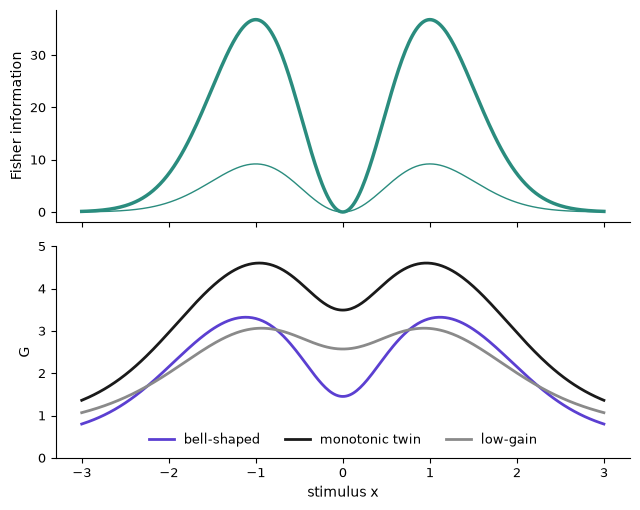

CPU times: user 89.3 ms, sys: 12.4 ms, total: 102 ms
Wall time: 125 ms


In [6]:
%%time

fig, (top, bottom) = plt.subplots(2, 1, figsize=(6.5, 5.2), sharex=True)
top.plot(x.cpu(), fisher["bell-shaped"].cpu(), color=TEAL, lw=2.5)
top.plot(x.cpu(), fisher["low-gain"].cpu(), color=TEAL, lw=1)
top.set_ylabel("Fisher information")
for name, values in g.items():
    bottom.plot(x.cpu(), values.cpu(), color=COLOURS[name], lw=2, label=name)
bottom.set_ylim(0, 5)
bottom.set_xlabel("stimulus x")
bottom.set_ylabel("G")
bottom.legend(loc="lower center", ncol=3)
fig.tight_layout()
plt.show()

The twin's $G$ is the largest at every stimulus, and the bell-shaped neuron's dips most at the peak.

## 4. The contribution of each scale

On a logarithmic axis of blur levels, $dt = t\, d\ln t$, so $t\,(\varphi_t * J_t)(x)$ is the contribution of each blur level per unit of $\ln t$, and its integral over $\ln t$ along a vertical line is $G(x)$. The map of this quantity over stimulus and blur level is the per-log-scale picture of $G$. The cell draws it for the bell-shaped neuron and its twin on one colour scale, with a contour at half the largest value.

time: <1 sec

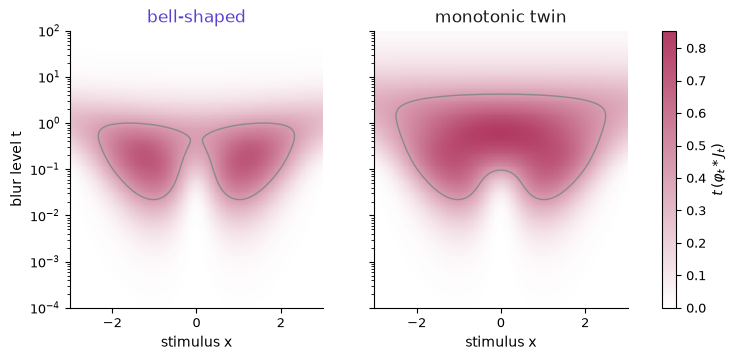

CPU times: user 326 ms, sys: 16 ms, total: 342 ms
Wall time: 372 ms


In [7]:
%%time

levels = blur[1:].cpu()  # t = 0 has no place on a logarithmic axis
per_log_scale = {
    name: (blur[1:, None] * multiscale[name].terms[1:]).cpu()
    for name in ("bell-shaped", "monotonic twin")
}
top_value = max(m.max().item() for m in per_log_scale.values())
rose_map = LinearSegmentedColormap.from_list("rose", ["#ffffff", ROSE])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, (name, values) in zip(axes, per_log_scale.items()):
    image = ax.pcolormesh(
        x.cpu(), levels, values, cmap=rose_map, vmin=0, vmax=top_value, shading="auto"
    )
    ax.contour(x.cpu(), levels, values, [top_value / 2], colors="#8a8a8a", linewidths=1)
    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1e2)
    ax.set_title(name, color=COLOURS[name])
    ax.set_xlabel("stimulus x")
axes[0].set_ylabel("blur level t")
fig.colorbar(image, ax=axes, label=r"$t\,(\varphi_t * J_t)$")
plt.show()

The two maps agree at fine blur levels, where the contribution is the Fisher information, the same for both neurons. At coarser blur levels the bell-shaped neuron contributes little near $x = 0$: a blurred stimulus near 0 could have come from either side of the peak, where the neuron gives the same responses. The twin contributes most there, and up to larger blur levels.

### 4.1. The blur levels at which the two neurons part

The cell finds the blur level at $x = -1$ from which the contributions of the two neurons differ by more than 5%, and from which the bell-shaped neuron's is less than half of the twin's.

time: <1 sec

In [8]:
%%time


def from_level(condition):
    """The first blur level from which `condition` holds at every larger level."""
    fails = (~condition).nonzero()
    return blur[fails.max() + 1].item() if len(fails) else blur[0].item()


i_flank = (x + 1).abs().argmin()
bell_terms = multiscale["bell-shaped"].terms[:, i_flank]
twin_terms = multiscale["monotonic twin"].terms[:, i_flank]
part_5 = from_level((bell_terms - twin_terms).abs() > 0.05 * twin_terms)
part_half = from_level(bell_terms < 0.5 * twin_terms)
print(
    f"x = -1: differ by more than 5% from t = {part_5:.2f}, less than half from "
    f"t = {part_half:.2f}"
)

x = -1: differ by more than 5% from t = 0.18, less than half from t = 1.27
CPU times: user 389 μs, sys: 377 μs, total: 766 μs
Wall time: 2.03 ms


At $x = -1$ the two contributions differ by more than 5% from $t = 0.18$ on. The bell-shaped neuron's is less than half of the twin's from $t = 1.3$ on (1.2 on the converged grid of blur levels, one step of this grid away).

The cell gives the share of $G$ that comes from blur levels above $t = 1$, at $x = -1$ and at the peak.

time: <1 sec

In [9]:
%%time


def share_above(name, x0, t0=1.0):
    """The share of G(x0) from blur levels above t0, with linear interpolation at t0."""
    terms = multiscale[name].terms[:, (x - x0).abs().argmin()]
    so_far = torch.cat([terms.new_zeros(1), torch.cumulative_trapezoid(terms, blur)])
    k = (blur < t0).nonzero().max()
    w = (t0 - blur[k]) / (blur[k + 1] - blur[k])
    return 1 - ((1 - w) * so_far[k] + w * so_far[k + 1]).item() / so_far[-1].item()


share_above_1 = {(n, x0): share_above(n, x0) for n in per_log_scale for x0 in (-1, 0)}
for (name, x0), share in share_above_1.items():
    print(f"{name:15s}, x = {x0:2d}: {share:.0%} of G from t > 1")

bell-shaped    , x = -1: 12% of G from t > 1
bell-shaped    , x =  0: 25% of G from t > 1
monotonic twin , x = -1: 30% of G from t > 1
monotonic twin , x =  0: 42% of G from t > 1
CPU times: user 594 μs, sys: 373 μs, total: 967 μs
Wall time: 2 ms


Blur levels above $t = 1$ give 12% of $G(-1)$ for the bell-shaped neuron and 30% for the twin, and 25% and 42% at the peak (41% on the converged grid). The twin keeps adding to its $G$ at blur levels where the bell-shaped neuron has little left to add.

## 5. Distances

A metric measures lengths. The length of the path from $a$ to $b$ along the stimulus axis is $\int_a^b \sqrt{M(x)}\, dx$ for the metric $M$: with $M = J$ it is the Fisher distance $d_J(a, b)$, with $M = G$ the G distance $d_G(a, b)$. `distance` computes it with the trapezoid rule. The cell computes both distances from one end of the axis to the other and from $-1$ to $1$, next to the mutual information.

time: <1 sec

In [10]:
%%time

distances = {
    name: {
        "d_J(-3, 3)": distance(x, fisher[name], -3, 3).item(),
        "d_G(-3, 3)": distance(x, g[name], -3, 3).item(),
        "d_J(-1, 1)": distance(x, fisher[name], -1, 1).item(),
        "d_G(-1, 1)": distance(x, g[name], -1, 1).item(),
    }
    for name in neurons
}
print(
    f"{'':15s}  "
    + "  ".join(f"{k:>10s}" for k in distances["low-gain"])
    + "  I(R; X) bits"
)
for name, row in distances.items():
    print(
        f"{name:15s}  "
        + "  ".join(f"{v:10.2f}" for v in row.values())
        + f"  {mi_bits[name]:12.2f}"
    )

                 d_J(-3, 3)  d_G(-3, 3)  d_J(-1, 1)  d_G(-1, 1)  I(R; X) bits
bell-shaped           19.78        8.79        7.87        3.07          1.60
monotonic twin        19.78       10.85        7.87        4.05          2.42
low-gain               9.89        9.02        3.93        3.37          1.66
CPU times: user 1.84 ms, sys: 259 μs, total: 2.1 ms
Wall time: 2.69 ms


From one end of the axis to the other the Fisher distance is 19.78 for the bell-shaped neuron and its twin and 9.89 for the low-gain neuron. The G distances are 8.79, 10.85 and 9.02 on this grid (8.78, 10.83 and 9.00 on the converged one). The twin comes first, the low-gain neuron second and the bell-shaped neuron last, the order of their mutual information (2.42, 1.66 and 1.60 bits). The G distances are not proportional to the bits. From $-1$ to $1$, where the bell-shaped neuron gives the same response distributions at both ends, $d_J = 7.87$ for both neurons, while $d_G$ is 3.07 and 4.05 (3.06 and 4.04 on the converged grid). The low-gain neuron has $d_J = 3.93$ and $d_G = 3.37$ there. The two stimuli are distinct in $G$, but closer for the bell-shaped neuron.

### 5.1. Figure: Fisher distance and G distance

The distance from $x = -3$ to each stimulus, with $J$ (left) and with $G$ (right).

time: <1 sec

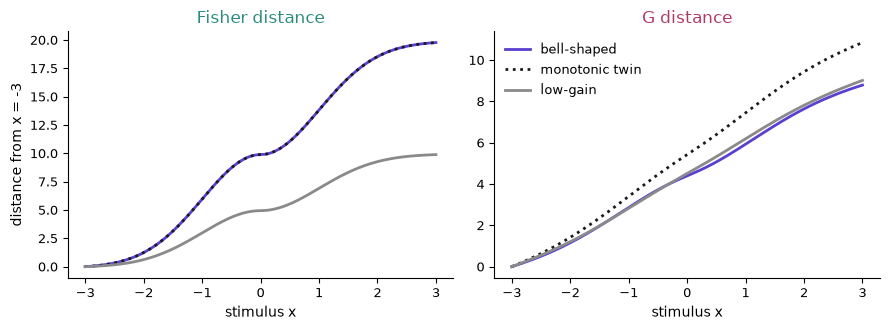

CPU times: user 93.8 ms, sys: 5.5 ms, total: 99.3 ms
Wall time: 107 ms


In [11]:
%%time

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for name in neurons:
    for ax, metric in zip(axes, (fisher[name], g[name])):
        ax.plot(
            x.cpu(),
            cumulative_distance(x, metric).cpu(),
            color=COLOURS[name],
            lw=2,
            label=name,
            ls=":" if name == "monotonic twin" else "-",
        )
axes[0].set_title("Fisher distance", color=TEAL)
axes[1].set_title("G distance", color=ROSE)
for ax in axes:
    ax.set_xlabel("stimulus x")
axes[0].set_ylabel("distance from x = -3")
axes[1].legend(loc="upper left")
fig.tight_layout()
plt.show()

Left: the bell-shaped neuron and its twin (dotted) have the same Fisher distance at every stimulus. Right: their G distances part at the peak, and the twin ends highest.

## 6. A change of unit

Measure the stimulus in a new unit, $y = c\,x$. The blur stays Gaussian with the same shape, blur level $t$ on $x$ becomes $c^2 t$ on $y$, and $J$ is divided by $c^2$. The two factors cancel in the integral over blur levels, so $G$ is unchanged at every stimulus and every G distance is multiplied by $c$. The Fisher distance does not change at all. The cell computes the bell-shaped neuron on the grid $y = 2x$, with the prior $1/12$ on $[-6, 6]$ and the same responses.

time: <1 sec

In [12]:
%%time

UNIT = 2.0  # the factor c of the change of unit
y = UNIT * x
g_y = compute_g(y, bell, prior / UNIT, SIGMA, blur).g
fisher_y = compute_fisher(y, bell, SIGMA)

unit_gap = (g_y - g["bell-shaped"]).abs().max().item()
print(f"largest |G in y - G in x|: {unit_gap:.4f} (largest G: {g_y.max().item():.2f})")
print(
    f"G distance:      {distance(y, g_y, -6, 6).item():.3f} in y, "
    f"{UNIT} x {distances['bell-shaped']['d_G(-3, 3)']:.3f} in x"
)
print(
    f"Fisher distance: {distance(y, fisher_y, -6, 6).item():.3f} in y, "
    f"{distances['bell-shaped']['d_J(-3, 3)']:.3f} in x"
)

largest |G in y - G in x|: 0.0000 (largest G: 3.32)
G distance:      17.581 in y, 2.0 x 8.790 in x
Fisher distance: 19.776 in y, 19.776 in x
CPU times: user 497 ms, sys: 124 ms, total: 621 ms
Wall time: 522 ms


$G$ is unchanged to four decimals. The blur levels are the same numbers in both units, so they fall on different scales, and this moves $G$ by less than $10^{-4}$. The G distance doubles and the Fisher distance stays the same. The G distance therefore has the unit of the stimulus, and the constant factor of $G$ that the requirements leave open is the choice of that unit.

## 7. Try it

1. Halve the noise, `SIGMA = 0.05`, and rerun. $J$ grows four times, while $G$ grows by about $\ln 4 = 1.39$ where the neuron is informative: $G$ grows with the logarithm of the signal-to-noise ratio.
2. Change the prior to a Gaussian with standard deviation 1, which makes the ends of the axis rare. $G$ changes, although $J$ does not depend on the prior.
3. Give the twin a smaller step, $m(x) = 1.5 - f(x)$ for $x \ge 0$, and watch its G distance approach the bell-shaped neuron's.

The cell carries out the second change for the bell-shaped neuron and its twin.

time: 1 sec

bell-shaped    : d_G(-3, 3) = 8.14 with the Gaussian prior, 8.79 with the uniform one


monotonic twin : d_G(-3, 3) = 9.35 with the Gaussian prior, 10.85 with the uniform one


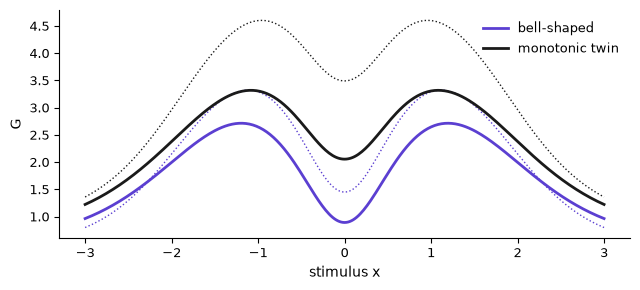

CPU times: user 1.09 s, sys: 273 ms, total: 1.36 s
Wall time: 1.3 s


In [13]:
%%time

gaussian_prior = torch.exp(-(x**2) / 2)
gaussian_prior = gaussian_prior / torch.trapezoid(gaussian_prior, x)

fig, ax = plt.subplots(figsize=(6.5, 3))
for name in ("bell-shaped", "monotonic twin"):
    g_gauss = compute_g(x, neurons[name], gaussian_prior, SIGMA, blur).g
    ax.plot(x.cpu(), g[name].cpu(), color=COLOURS[name], lw=1, ls=":")
    ax.plot(x.cpu(), g_gauss.cpu(), color=COLOURS[name], lw=2, label=name)
    print(
        f"{name:15s}: d_G(-3, 3) = {distance(x, g_gauss, -3, 3).item():.2f} with the "
        f"Gaussian prior, {distances[name]['d_G(-3, 3)']:.2f} with the uniform one"
    )
ax.set_xlabel("stimulus x")
ax.set_ylabel("G")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

With the Gaussian prior (solid) both $G$ curves are lower than with the uniform prior (dotted) on the flanks and at the peak, the twin's by about 1.4 at the peak, and the G distances shrink. The Fisher information of section 2 is the same under both priors. With fewer stimuli far from the centre, fewer distant stimuli become confusable at coarse blur levels, and the coarse blur levels add less to $G$.